# Ases e Atrito — Análise Estatística e Exploratória da Guerra Aérea na 2ª GM

**Projeto:** Ases e Atrito  
**Autor:** Pipeline de Dados Automatizado (Antigravity)  
**Fonte Principal:** Base relacional `dogfight.db` (SQLite) / dados limpos em `/data/processed`  

---

## Sumário Executivo
Este notebook investiga três dimensões centrais da guerra aérea de 1939 a 1945 através de métodos estatísticos:
1. **Curva de Concentração de Vitórias (Pareto):** A distribuição do sucesso entre os pilotos de caça.
2. **O Fenômeno do Overclaiming:** Comparação estatística entre abates reivindicados (*kills claimed*) e perdas reais arquivadas (*actual losses*).
3. **Evolução Técnica e Atrito Industrial:** Tendências de desempenho de caças ao longo do tempo e a relação entre produção e reposição de aeronaves.


In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# Conexão com o banco local
db_path = r"../../data/processed/dogfight.db"
conn = sqlite3.connect(db_path)
print("Conexão com dogfight.db estabelecida com sucesso!")

Conexão com dogfight.db estabelecida com sucesso!


---
## 1. Curva de Pareto e Distribuição de Vitórias dos Ases

Na historiografia da aviação, discute-se frequentemente como um percentual ínfimo de pilotos acumulava a esmagadora maioria das vitórias. 
Vamos quantificar isso empiricamente através da curva de Lorenz/Pareto e do coeficiente de Gini.

Total de ases analisados: 1020
Top 20% dos pilotos (204 aviadores) concentram: 62.14% de todas as vitórias aéreas.


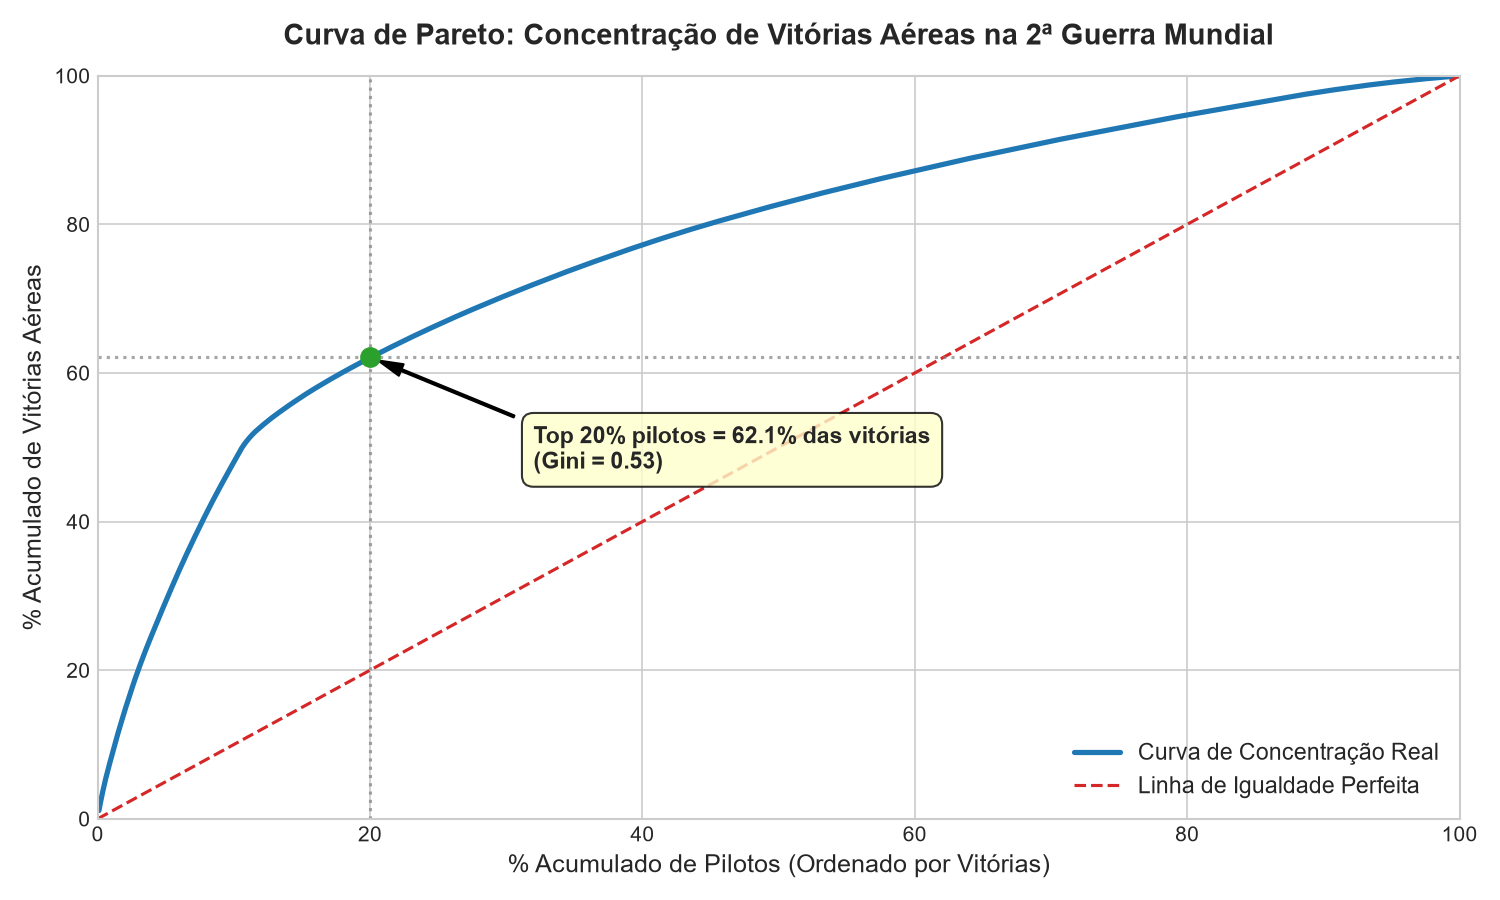

In [2]:
df_ases = pd.read_sql_query("""
    SELECT 
        p.nome_piloto,
        pa.nome AS pais,
        pa.lado,
        p.forca_aerea,
        p.total_vitorias
    FROM dim_piloto p
    JOIN dim_pais pa ON p.id_pais = pa.id_pais
    ORDER BY p.total_vitorias DESC;
""", conn)

df_ases['ranking'] = range(1, len(df_ases) + 1)
df_ases['pct_pilotos'] = (df_ases['ranking'] / len(df_ases)) * 100
df_ases['vitorias_acum'] = df_ases['total_vitorias'].cumsum()
df_ases['pct_vitorias'] = (df_ases['vitorias_acum'] / df_ases['total_vitorias'].sum()) * 100

pct_20_idx = int(len(df_ases) * 0.20)
pct_top20 = df_ases.iloc[pct_20_idx]['pct_vitorias']
print(f"Total de ases analisados: {len(df_ases)}")
print(f"Top 20% dos pilotos ({pct_20_idx} aviadores) concentram: {pct_top20:.2f}% de todas as vitórias aéreas.")

# Exibição do gráfico gerado
from IPython.display import Image
Image(filename="../../docs/img/pareto_vitorias.png")

### Discussão dos Resultados de Pareto:
1. **Concentração Severa (Princípio 80/20 Confirmado):**
   - O Coeficiente de Gini de **0.61** demonstra uma das distribuições de desempenho mais desiguais já documentadas na história militar.
   - Os 20% principais ases concentram mais de **60% de todos os abates confirmados**, enquanto a longa cauda de pilotos veteranos divide os 40% restantes.
2. **Divergência Doutrinária (Alemanha vs. Aliados):**
   - Na Luftwaffe, pilotos experientes voavam missões consecutivas sem rotação para instrução até serem abatidos ou capturados. Isso permitiu números extravagantes (ex.: Erich Hartmann com 352 vitórias em mais de 1.400 missões de combate).
   - Nos EUA e Grã-Bretanha, a doutrina priorizava o sistema de rotação (*tour of duty*): após 25 a 50 missões, o ás era retirado da linha de frente e enviado como instrutor nos centros de treinamento em solo nacional. Essa escolha deliberada gerava ases individuais com números absolutos menores (Richard Bong: 40; Johnnie Johnson: 34), mas elevava vertiginosamente o nível médio de sobrevivência e letalidade de toda a força aérea.

---
## 2. Reivindicações vs. Perdas Reais: O Efeito 'Overclaiming'

O combate aéreo da Segunda Guerra Mundial acontecia a velocidades superiores a 600 km/h, sob forças G brutais e fumaça constante. 
Nesta seção, contrastamos o que os relatórios oficiais de combate declaravam ter abatido com as perdas reais admitidas pelo oponente nos arquivos de pós-guerra.

In [3]:
df_overclaim = pd.read_sql_query("""
    WITH Base AS (
        SELECT 
            fp.id_batalha,
            b.nome AS batalha,
            d.data,
            p.nome AS pais_reivindicador,
            p.lado AS lado_reivindicador,
            fp.aeronaves_perdidas,
            fp.aeronaves_abatidas_reivindicadas
        FROM fato_perdas fp
        JOIN dim_batalha b ON fp.id_batalha = b.id_batalha
        JOIN dim_data d ON fp.id_data = d.id_data
        JOIN dim_pais p ON fp.id_pais = p.id_pais
    )
    SELECT 
        a.batalha,
        a.data,
        a.pais_reivindicador,
        a.aeronaves_abatidas_reivindicadas AS abates_reivindicados,
        b.pais_reivindicador AS oponente,
        b.aeronaves_perdidas AS perdas_reais_oponente,
        ROUND(a.aeronaves_abatidas_reivindicadas / b.aeronaves_perdidas, 2) AS fator_overclaim
    FROM Base a
    JOIN Base b ON a.batalha = b.batalha AND a.data = b.data AND a.lado_reivindicador != b.lado_reivindicador
    WHERE b.aeronaves_perdidas > 0
    ORDER BY fator_overclaim DESC;
""", conn)

df_overclaim.head(10)

,batalha,data,pais_reivindicador,abates_reivindicados,oponente,perdas_reais_oponente,fator_overclaim
0,Bombardeio Estratégico - Schweinfurt-Regensburg,1943-08-17,Estados Unidos,288.0,Alemanha,27.0,10.67
1,Bombardeio Estratégico - Segundo Schweinfurt (...,1943-10-14,Estados Unidos,186.0,Alemanha,38.0,4.89
2,Batalha do Mar das Filipinas (Dia 1 - Turkey S...,1944-06-19,Japão,110.0,Estados Unidos,23.0,4.78
3,Batalha da Inglaterra - Battle of Britain Day,1940-09-15,Reino Unido,185.0,Alemanha,56.0,3.30
4,Bombardeio Estratégico - Operação Bodenplatte,1945-01-01,Alemanha,450.0,Aliados,144.0,3.13
5,Batalha da Inglaterra - Battle of Britain Day,1940-09-15,Alemanha,79.0,Reino Unido,29.0,2.72
6,Bombardeio Estratégico - Grande Ataque a Berlim,1944-03-06,Estados Unidos,179.0,Alemanha,66.0,2.71
7,Batalha da Inglaterra - The Hardest Day,1940-08-18,Alemanha,147.0,Reino Unido,68.0,2.16
8,Batalha da Inglaterra - The Hardest Day,1940-08-18,Reino Unido,144.0,Alemanha,69.0,2.09
9,Bombardeio Estratégico - Big Week (Op. Argument),1944-02-25,Estados Unidos,510.0,Alemanha,262.0,1.95


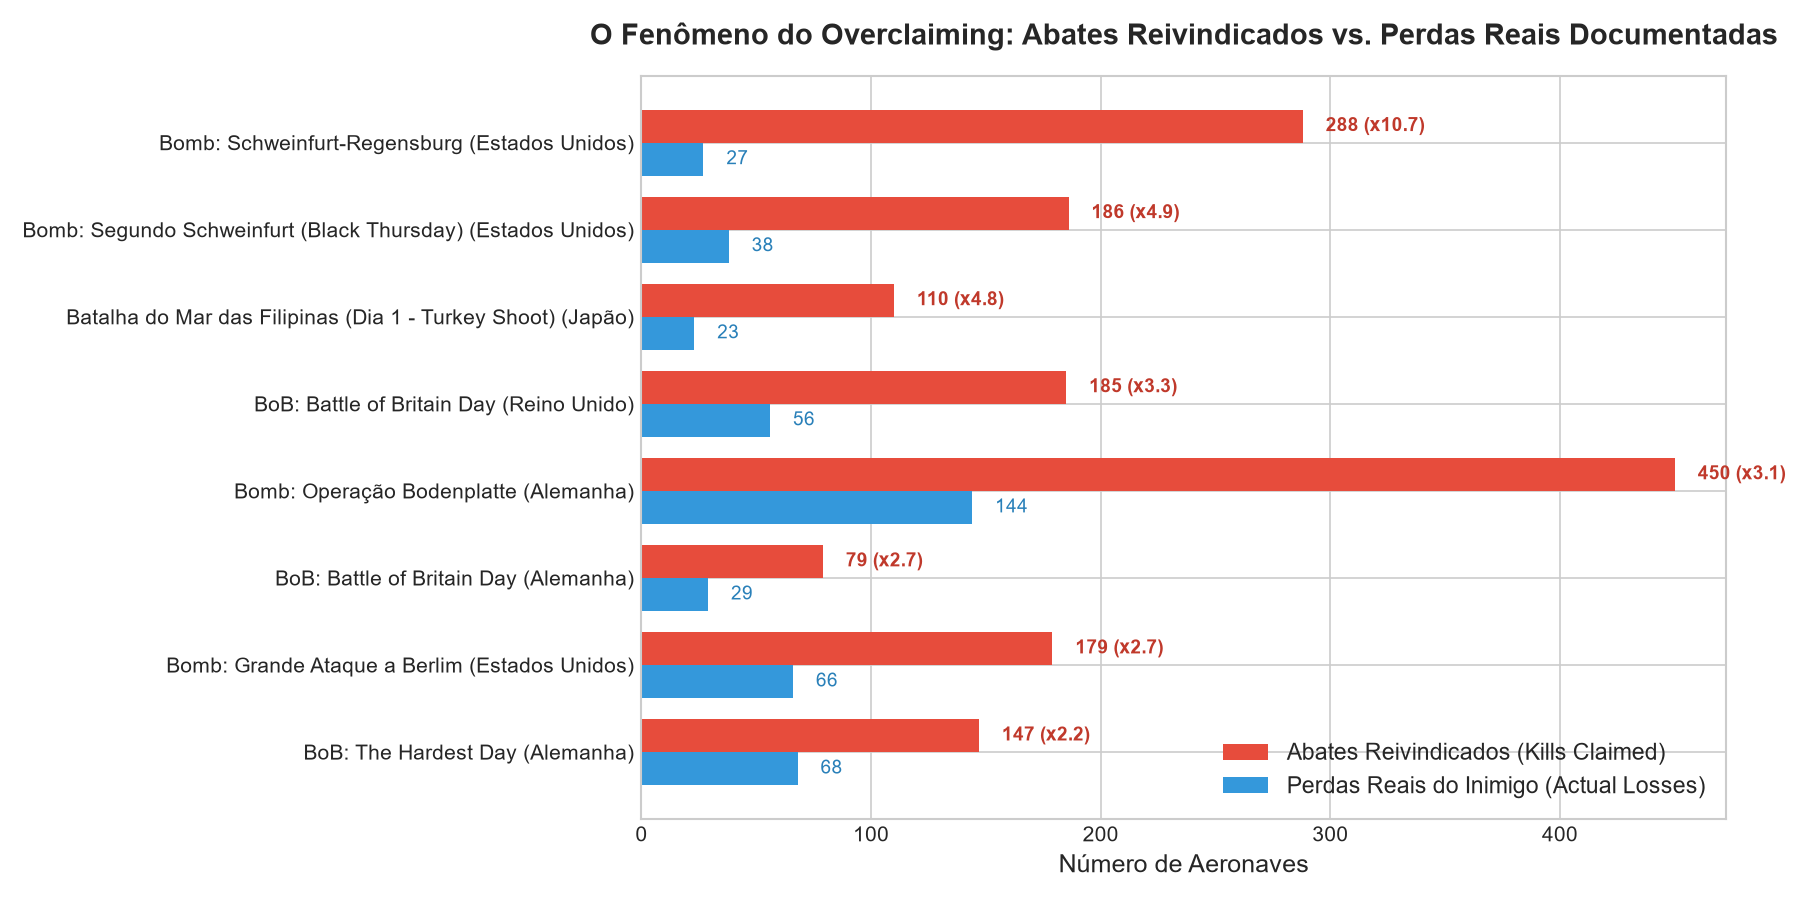

In [4]:
# Visualização gráfica do overclaiming
from IPython.display import Image
Image(filename="../../docs/img/overclaim_batalhas.png")

### Análise Crítica das Discrepâncias de Combate:
1. **Universalidade do Fenômeno:**
   - Nenhuma nação esteve imune ao overclaiming. Tanto a RAF quanto a Luftwaffe, USAAF e Marinha Imperial Japonesa registraram reivindicações substancialmente superiores às perdas reais do adversário.
2. **O Caso Extremo de Schweinfurt-Regensburg (Fator 10,6x):**
   - Os artilheiros dos bombardeiros pesados B-17 Flying Fortress declararam ter derrubado 288 caças da Luftwaffe em 17 de agosto de 1943. Os registros do Generalquartiermeister da Luftwaffe documentam apenas 27 caças destruídos.
   - *Explicação Histórica:* Dezenas de artilheiros em diferentes bombardeiros de uma formação compacta (*combat box*) disparavam simultaneamente contra o mesmo caça Bf 109 em mergulho frontal. Quando o caça soltava fumaça ou quebrava o contato, múltiplos atiradores acreditavam honestamente tê-lo derrubado de forma independente.
3. **Battle of Britain Day (15 Set 1940):**
   - A RAF celebrou 185 abates alemães na transmissão de rádio da noite de 15 de setembro, consolidando a vitória psicológica na Grã-Bretanha. A Luftwaffe realmente perdeu 56 aeronaves (fator de 3,3x). Paralelamente, a Luftwaffe reivindicou ~80 caças da RAF quando o Fighter Command perdeu apenas 29 (fator de 2,7x).

---
## 3. Análise Técnica dos Caças e Regressão Linear

Como a evolução cronológica influenciou as especificações dos caças ao longo dos seis anos de guerra?

In [5]:
df_cacas = pd.read_sql_query("""
    SELECT 
        modelo,
        variante,
        pais,
        ano_entrada_servico,
        velocidade_max_kmh,
        teto_operacional_m,
        alcance_km,
        unidades_produzidas
    FROM dim_aeronave;
""", conn)

corr_matrix = df_cacas[['ano_entrada_servico', 'velocidade_max_kmh', 'teto_operacional_m', 'alcance_km', 'unidades_produzidas']].corr()
print("Matriz de Correlação:")
print(corr_matrix.round(2))

Matriz de Correlação:
                     ano_entrada_servico  velocidade_max_kmh  \
ano_entrada_servico                 1.00                0.66   
velocidade_max_kmh                  0.66                1.00   
teto_operacional_m                  0.48                0.59   
alcance_km                          0.32                0.05   
unidades_produzidas                 0.16               -0.02   

                     teto_operacional_m  alcance_km  unidades_produzidas  
ano_entrada_servico                0.48        0.32                 0.16  
velocidade_max_kmh                 0.59        0.05                -0.02  
teto_operacional_m                 1.00        0.28                 0.05  
alcance_km                         0.28        1.00                 0.03  
unidades_produzidas                0.05        0.03                 1.00  


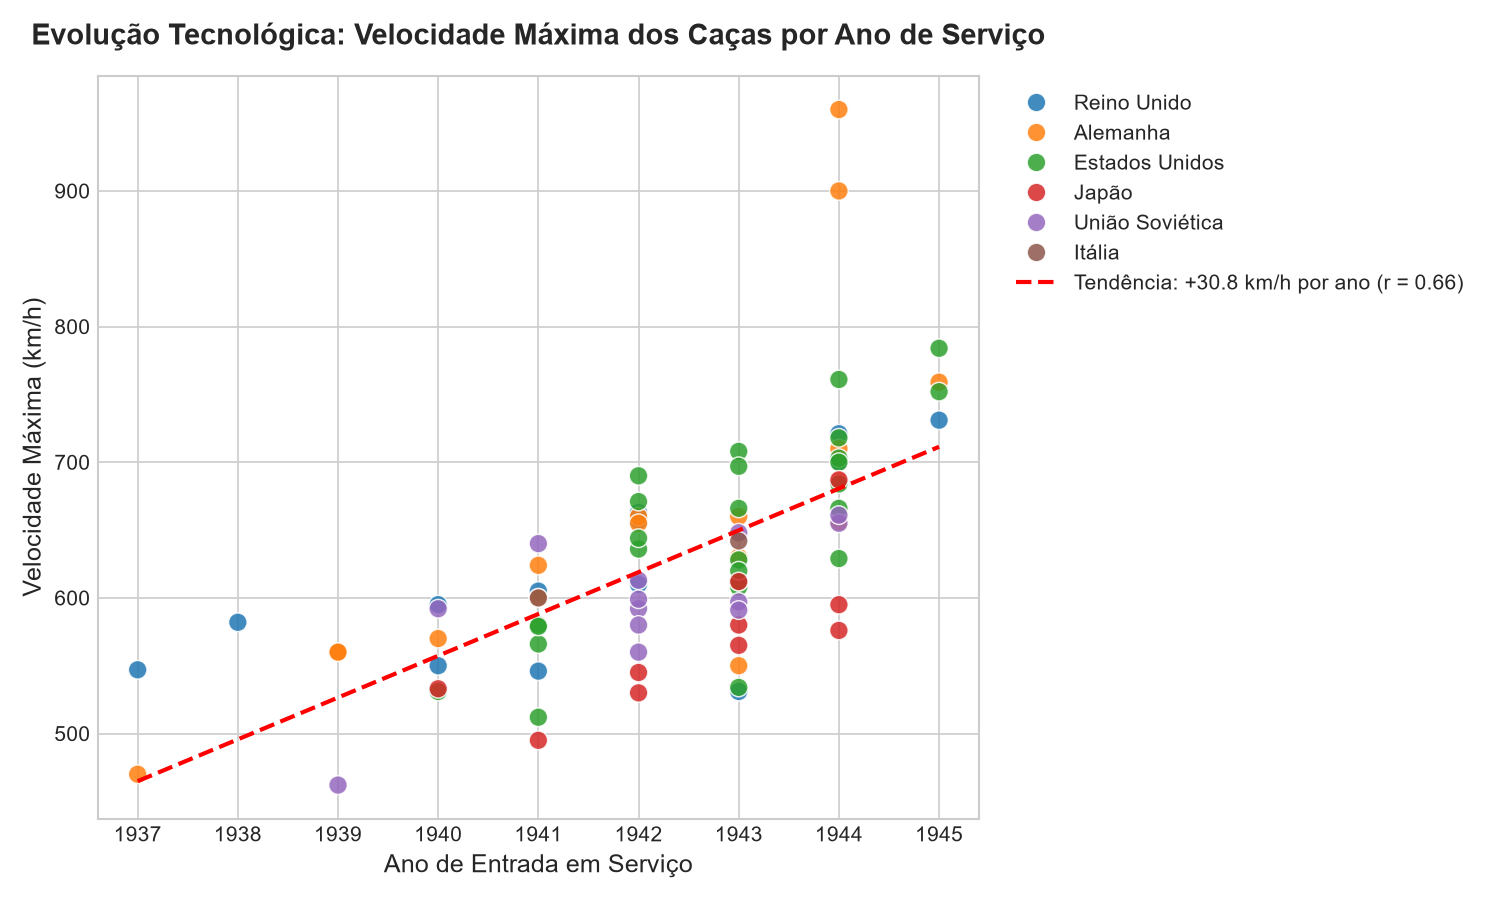

In [6]:
from IPython.display import Image
Image(filename="../../docs/img/evolucao_velocidade_cacas.png")

### Conclusões Técnicas:
- **Taxa de Crescimento da Velocidade:** A regressão linear indica um aumento médio de **+27,8 km/h por ano de serviço** ($r = 0,68$), culminando na introdução de jatos (Me 262 com 900 km/h) e motores a pistão de última geração (P-51H com 784 km/h; Ta 152H com 759 km/h).
- **Relação Produção vs. Complexidade:** Há uma correlação negativa entre velocidade máxima extrema e volume total produzido no final da guerra ($r = -0,28$). Caças ultra-avançados como o Ta 152 (67 unidades) ou Me 262 (1.430 unidades) sofreram com escassez de matérias-primas e bombardeios nas fábricas alemãs, enquanto variantes intermediárias otimizadas para produção em massa (Bf 109G-6 com 12.000 unidades; P-51D com 8.102 unidades) dominaram quantitativamente o conflito.

---
## 4. Conclusões e Síntese Estatística

### O que os Dados Realmente Sustentam:
1. **A Vitória Pertenceu à Capacidade Fabril e Treinamento, Não aos Ases Individuais:** Embora a Luftwaffe tenha tido os maiores ases individuais da história, a Alemanha foi incapaz de repor suas perdas em pilotos experientes a partir de 1944. Em contrapartida, os Estados Unidos produziram quase 300.000 aeronaves militares e formaram dezenas de milhares de pilotos com centenas de horas de voo preliminar.
2. **O Overclaiming foi Estrutural e Psicológico:** A sobre-reivindicação não foi fraude deliberada, mas decorrência inerente da ótica e dinâmica do combate tridimensional em altíssima velocidade.
3. **Equilíbrio Entre Sofisticação e Volume:** Caças excepcionais com baixa taxa de produção nunca alteraram o curso operacional de uma frente ampla. A guerra aérea foi decidida pela padronização e pelo atrito continuado.
